# Lab 10: Spatial Interpolation

You will estimate a continuous surface from scattered sensors, check the estimates honestly, and then move counts from one set of polygons to another.

**What you do**

1. Predict temperature everywhere from a few thousand sensor readings, with nearest neighbors, k nearest neighbors and kriging.
2. Measure the semivariance between pairs of points and fit a variogram model.
3. Score each method with random and spatially blocked cross-validation.
4. Move 2020 census tract counts onto block groups and compare with the block group counts the census published.

**How this notebook works.** It runs top to bottom. Cells marked **🔎 Try it yourself** are not graded. The graded tasks are in `lab10-tasks.ipynb`.

**Packages.** `geopandas` (tables of geometries), `numpy` (arrays), `scikit-learn` (neighbors and cross-validation), `libpysal` and `esda` (spatial weights and Moran's I), `pyinterpolate` (variograms and kriging), `matplotlib` (plots). `pyinterpolate` is not in the standard I-GUIDE environment, so the first cell installs it if it is missing.

## Part 0. Setup

In [1]:
import sys, subprocess, warnings
from importlib.metadata import version
warnings.filterwarnings("ignore")
try:
    import pyinterpolate as pi
except ImportError:                       # not installed in this kernel yet
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pyinterpolate"])
    import pyinterpolate as pi
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt

print("Python", sys.version.split()[0], "| geopandas", gpd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| pyinterpolate", version("pyinterpolate"))

Python 3.8.16 | geopandas 0.13.2 | numpy 1.24.3 | matplotlib 3.7.1 | pyinterpolate 1.2.1


The cell below defines the helper functions used in every part. Read them once: each is short, and each is called by name later.

- `load_heat` reads one Heat Watch file and keeps one point per 250 m cell.
- `make_grid` makes the grid of locations where we will predict.
- `predict_knn`, `fit_variogram` and `predict_krige` are thin wrappers around `scikit-learn` and `pyinterpolate`.
- `show_surface` and `blank` draw maps with no ticks.
- `block_ids` labels each point with its 5 km square, used for blocked cross-validation in Part 5.

In [2]:
import shapely
from shapely.geometry import MultiPoint
from sklearn.neighbors import KNeighborsRegressor

PURPLE, MAGENTA, BLUE = "#7C3AED", "#DB2777", "#2563EB"


def blank(ax):
    """Map style: no ticks, no frame, equal aspect."""
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    for s in ax.spines.values():
        s.set_visible(False)


def load_heat(window):
    """One Heat Watch window ("am", "af" or "pm"), thinned to one point per 250 m cell. Returns x, y (meters) and F."""
    heat = gpd.read_file(f"data/heat/{window}_trav.shp")
    heat = heat[heat["t_f"] > -9000].to_crs(32614)                  # drop removed readings; metric CRS
    xy = np.column_stack([heat.geometry.x, heat.geometry.y])
    cell = (xy // 250).astype(int)
    _, keep = np.unique(cell, axis=0, return_index=True)            # first point in each 250 m cell
    keep = np.sort(keep)
    return xy[keep], heat["t_f"].to_numpy()[keep], len(heat)


def make_grid(xy, n=60):
    """n by n grid of prediction locations over the points, and a flag for the ones inside their convex hull."""
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    gx, gy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    U = np.column_stack([gx.ravel(), gy.ravel()])
    inside = shapely.contains_xy(MultiPoint(xy).convex_hull, U[:, 0], U[:, 1])
    return gx, gy, U, inside


def predict_knn(xy, t, U, k=15, weights="distance"):
    """k nearest neighbors. k = 1 is nearest neighbor; weights "uniform" or "distance" (inverse distance)."""
    return KNeighborsRegressor(n_neighbors=k, weights=weights).fit(xy, t).predict(U)


def fit_variogram(xy, t, model="exponential", step=1000, max_range=15000):
    """Experimental variogram (1 km lags to 15 km) and a fitted model with pyinterpolate."""
    known = np.column_stack([xy, t])
    ex = pi.build_experimental_variogram(known, step_size=step, max_range=max_range)
    return ex, pi.build_theoretical_variogram(ex, models_group=model)


def predict_krige(xy, t, U, model="exponential", fitted=None, k=16):
    """Ordinary kriging. Returns the prediction and the variance error at each row of U."""
    th = fitted if fitted is not None else fit_variogram(xy, t, model)[1]
    out = pi.interpolate_points(th, unknown_locations=U, known_locations=np.column_stack([xy, t]),
                                no_neighbors=k, allow_approximate_solutions=True, progress_bar=False)
    return out[:, 0], out[:, 1]


def show_surface(ax, gx, gy, z, inside, vmin, vmax, title, cmap="YlOrRd"):
    """Draw a gridded surface; grid cells outside the data's convex hull are left blank."""
    zz = np.where(inside, z, np.nan).reshape(gx.shape)
    im = ax.pcolormesh(gx, gy, zz, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    ax.set_title(title)
    blank(ax)
    return im


def block_ids(xy, size=5000):
    """Label each point with the 5 km by 5 km square it falls in."""
    return (xy[:, 0] // size).astype(int) * 1000 + (xy[:, 1] // size).astype(int)

## Part 1. The data: Heat Watch Dallas

**Heat Watch Dallas** was a one-day field campaign on **August 5, 2023**, run by the City of Dallas Office of Environmental Quality and Sustainability with NOAA and CAPA Strategies. Volunteers drove nine routes across the city with a temperature and humidity sensor mounted on the car and a GPS. The sensor logged one reading per second in three windows: morning (6 to 7 am), afternoon (3 to 4 pm) and evening (7 to 8 pm).

**One row** is one reading: a point with `t_f` (air temperature, degrees F), `rh` (relative humidity, percent) and `hi_f` (heat index, degrees F). The data are public on the Open Science Framework (https://osf.io/3hy75/).

This lab uses the **evening** window (`pm`). The readings sit along the routes, so a car moving slowly gives many points within a few meters of each other. Interpolation methods need locations that are distinct, so `load_heat` keeps one point per 250 m by 250 m cell.

19517 usable readings; 1047 after thinning to one per 250 m cell
temperature 96.2 to 105.6 F, mean 102.4, SD 0.92


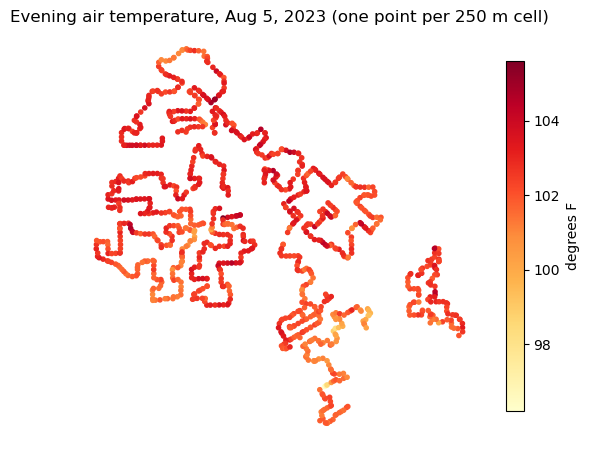

In [3]:
xy, t, n_all = load_heat("pm")
print(n_all, "usable readings;", len(t), "after thinning to one per 250 m cell")
print(f"temperature {t.min():.1f} to {t.max():.1f} F, mean {t.mean():.1f}, SD {t.std():.2f}")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=t, s=9, cmap="YlOrRd")
blank(ax)
ax.set_title("Evening air temperature, Aug 5, 2023 (one point per 250 m cell)")
fig.colorbar(sc, ax=ax, shrink=0.7, label="degrees F")
plt.show()

The coordinates are in meters (EPSG:32614, UTM zone 14N). Distances in every method below are computed in meters, which is why the data are reprojected first.

**Predicting one value by hand.** Hold out one point, hide its temperature, and predict it from the 5 points nearest to it. The error tells you how well "the average of nearby values" does.

In [4]:
i = 100                                          # the held-out point
others = np.delete(np.arange(len(t)), i)
nearest = KNeighborsRegressor(n_neighbors=5).fit(xy[others], t[others])
dist, idx = nearest.kneighbors(xy[[i]])
print("distances to the 5 nearest points (m):", dist[0].round(0))
print("their temperatures (F):", t[others][idx[0]])
print(f"prediction {t[others][idx[0]].mean():.2f} F, measured {t[i]:.2f} F")

distances to the 5 nearest points (m): [197. 267. 334. 377. 402.]
their temperatures (F): [102.  101.7 101.8 101.6 102. ]
prediction 101.82 F, measured 102.00 F


**Is there spatial structure at all?** Interpolation only makes sense if nearby points are more alike than distant ones. **Moran's I** measures that: it is the correlation between each point's value and the average value of its $k$ nearest neighbors. It is near 0 for no structure and near 1 when neighbors are very alike. The `p` is from 999 random shuffles of the values over the same locations: how often does shuffling give a Moran's I this large?

In [5]:
from libpysal.weights import KNN
from esda.moran import Moran


def morans_i(xy, t, k=8, seed=0):
    """Moran's I of the values at the points, with k-nearest-neighbor weights (row-standardized)."""
    w = KNN.from_array(xy, k=k)
    w.transform = "r"
    np.random.seed(seed)
    m = Moran(t, w, permutations=999)
    return m.I, m.p_sim

In [6]:
I, p = morans_i(xy, t, k=8)
print(f"Moran's I = {I:.2f} (p = {p:.3f}) with 8 nearest neighbors")

Moran's I = 0.61 (p = 0.001) with 8 nearest neighbors


**🔎 Try it yourself.** Change `i` to another number and repeat. Then change `n_neighbors` to 1 and to 20. Does a single neighbor or the average of many do better at your points?

## Part 2. Nearest and k-nearest neighbors

Two ways to predict at a new location $u$:

- **Nearest neighbor** copies the value of the closest sensor. The surface is a mosaic of flat patches.
- **k nearest neighbors (kNN)** averages the $k$ closest sensors. With `weights="uniform"` each counts equally. With `weights="distance"` each is weighted by inverse distance, $w_i \propto 1/d_i$, which is inverse distance weighting with power 1.

We predict on a 60 by 60 grid and blank the cells outside the convex hull of the points, because predictions far from any sensor are extrapolation.

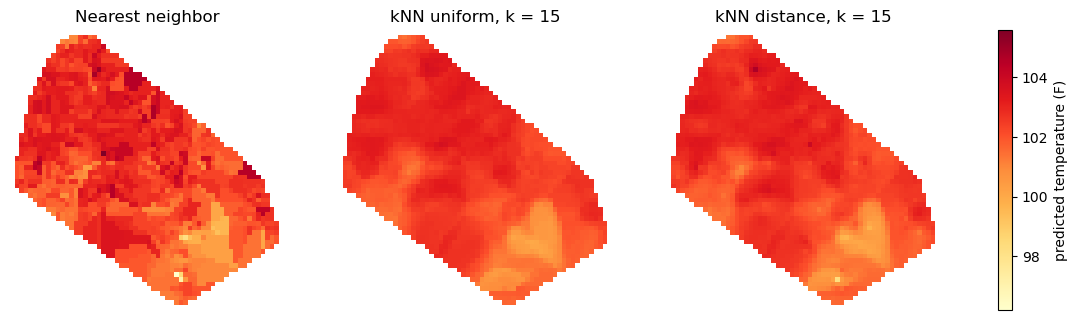

Nearest neighbor       range 96.2 to 105.6 F
kNN uniform, k = 15    range 100.0 to 103.7 F
kNN distance, k = 15   range 98.3 to 104.7 F


In [7]:
gx, gy, U, inside = make_grid(xy)
vmin, vmax = t.min(), t.max()

surfaces = {
    "Nearest neighbor": predict_knn(xy, t, U, k=1),
    "kNN uniform, k = 15": predict_knn(xy, t, U, k=15, weights="uniform"),
    "kNN distance, k = 15": predict_knn(xy, t, U, k=15, weights="distance"),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, (name, z) in zip(axes, surfaces.items()):
    im = show_surface(ax, gx, gy, z, inside, vmin, vmax, name)
fig.colorbar(im, ax=axes, shrink=0.7, label="predicted temperature (F)")
plt.show()
for name, z in surfaces.items():
    print(f"{name:22s} range {z[inside].min():.1f} to {z[inside].max():.1f} F")

Nearest neighbor keeps the full range of the data and shows hard edges. Averaging 15 neighbors smooths the surface and shrinks the range: an average cannot be higher than its highest member, and it rarely is.

**Choosing k.** Same method, same data, three values of $k$, one shared color scale.

k =  3  range 97.2 to 105.1 F
k = 15  range 98.3 to 104.7 F
k = 50  range 98.9 to 104.2 F


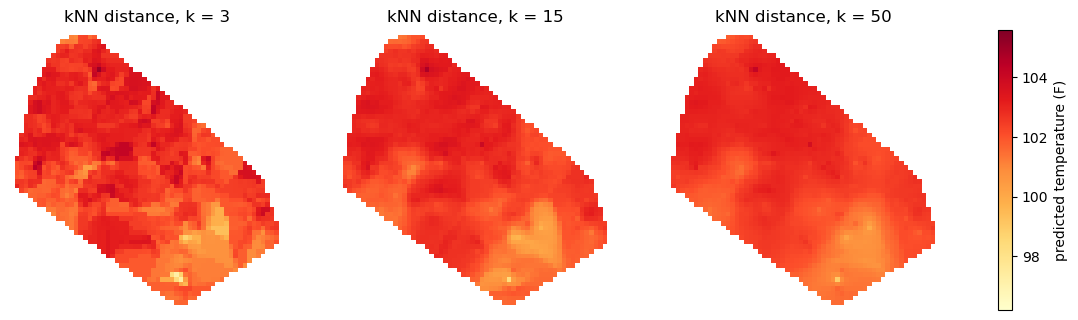

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, k in zip(axes, (3, 15, 50)):
    z = predict_knn(xy, t, U, k=k)
    im = show_surface(ax, gx, gy, z, inside, vmin, vmax, f"kNN distance, k = {k}")
    print(f"k = {k:2d}  range {z[inside].min():.1f} to {z[inside].max():.1f} F")
fig.colorbar(im, ax=axes, shrink=0.7, label="predicted temperature (F)")
plt.show()

**🔎 Try it yourself.** Use `weights="uniform"` in the loop above. Where on the map do uniform and distance weights differ most, and why would they differ there?

## Part 3. Semivariance and the variogram

kNN uses a fixed rule for how far to look and how to weight. **Kriging** instead measures, from the data, how fast similarity falls off with distance, and uses that to choose weights. The measure is the **semivariance**.

For two points at distance $h$ apart, half the squared difference of their values is a semivariance. Averaged over all pairs about $h$ apart:

$$\gamma(h) = \frac{1}{2\,N(h)} \sum_{i=1}^{N(h)} \big(z(x_i) - z(x_i + h)\big)^2$$

- $z(x_i)$ is the temperature measured at point $x_i$, and $z(x_i + h)$ is the temperature at a point $h$ meters away.
- $N(h)$ is the number of pairs of points about $h$ meters apart.
- The sum adds up the squared differences, and the $\tfrac12$ makes $\gamma$ comparable to a variance: if two points were unrelated, the average squared difference would be $2\sigma^2$, so $\gamma$ would equal the variance $\sigma^2$.

**Reading it:** small $\gamma(h)$ means points $h$ apart are alike. A large $\gamma(h)$ means they are as different as two random points.

**One distance by hand.** Every pair of points whose distance is between 2.5 and 3.5 km:

In [9]:
from scipy.spatial.distance import pdist

d = pdist(xy)                                           # distance between every pair of points (m)
sq = pdist(t.reshape(-1, 1), "sqeuclidean")             # squared difference in temperature for the same pairs
pair = (d >= 2500) & (d < 3500)
print(f"{pair.sum():,} pairs about 3 km apart")
print(f"semivariance at 3 km = {0.5 * sq[pair].mean():.2f} F^2")
print(f"variance of all temperatures = {t.var():.2f} F^2")

27,168 pairs about 3 km apart
semivariance at 3 km = 0.65 F^2
variance of all temperatures = 0.85 F^2


Now do this for every 1 km distance up to 15 km with `pyinterpolate`. The result is the **experimental variogram**: one semivariance per distance bin. The dashed line is the variance of the data.

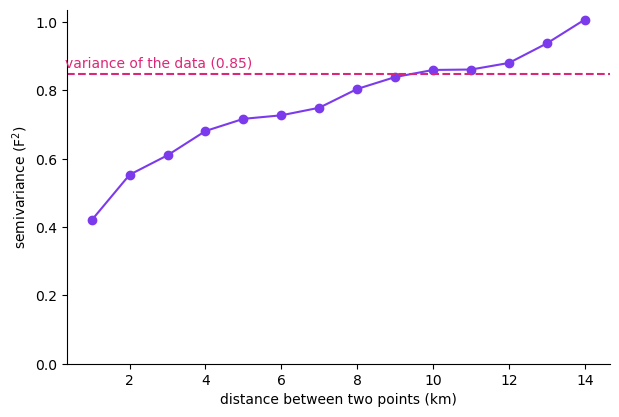

pyinterpolate's semivariance at 3 km: 0.61 F^2 (bins are drawn slightly differently from our hand calculation)


In [10]:
known = np.column_stack([xy, t])                        # x, y, value
exp_var = pi.build_experimental_variogram(known, step_size=1000, max_range=15000)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(exp_var.lags / 1000, exp_var.semivariances, "o-", color=PURPLE)
ax.axhline(t.var(), color=MAGENTA, ls="--")
ax.text(0.3, t.var() + 0.02, f"variance of the data ({t.var():.2f})", color=MAGENTA)
ax.set_xlabel("distance between two points (km)")
ax.set_ylabel("semivariance (F$^2$)")
ax.set_ylim(0, None)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
at3 = exp_var.semivariances[np.isclose(exp_var.lags, 3000)][0]
print(f"pyinterpolate's semivariance at 3 km: {at3:.2f} F^2 (bins are drawn slightly differently from our hand calculation)")

Nearby points are much more alike than distant points: the semivariance is about half the variance at 1 km and reaches the variance near 9 km. That is spatial structure, which kriging uses. The curve keeps rising past the variance at long distances, which means the temperature also changes steadily across the study area (a trend), so only the short-distance part of the curve is used.

**Fitting a model.** Kriging needs semivariance at any distance, not only at the bins, so we fit a smooth curve. A model has three numbers:

- **nugget**: the semivariance at distance near zero. It is variation at a scale smaller than the point spacing, plus measurement error.
- **range**: the distance where the curve levels off. Points farther apart than this are unrelated.
- **sill** (as `pyinterpolate` reports it, the *partial sill*): the height of the rise above the nugget. The plateau is nugget plus sill.

Three common shapes are the spherical, exponential and Gaussian models. They differ in how the curve approaches the plateau. We fit all three and compare the fit error.

In [11]:
models = {}
for name in ["spherical", "exponential", "gaussian"]:
    m = pi.build_theoretical_variogram(exp_var, models_group=name)
    models[name] = m
    print(f"{name:12s} nugget {m.nugget:.2f}  sill {m.sill:.2f}  range {m.rang / 1000:4.1f} km  fit error {m.rmse:.3f}")

spherical    nugget 0.21  sill 0.67  range  8.2 km  fit error 0.070
exponential  nugget 0.21  sill 0.73  range  4.0 km  fit error 0.042
gaussian     nugget 0.21  sill 0.67  range  3.2 km  fit error 0.089


The exponential model has the lowest fit error here, so the rest of the lab uses it unless a task says otherwise. (Naming the model, `models_group="exponential"`, is deliberate: the default `"safe"` choice can pick a model that makes the kriging system impossible to solve.)

**🔎 Try it yourself.** Rebuild the experimental variogram with `step_size=500` and `max_range=10000`. Does the nugget change? What does that tell you about how well the nugget is known?

## Part 4. Ordinary kriging

Ordinary kriging predicts at $u$ as a weighted sum of the nearby sensor values:

$$\hat z(u) = \sum_{i=1}^{n} \lambda_i \, z(x_i), \qquad \sum_{i=1}^{n} \lambda_i = 1$$

- $\hat z(u)$ is the predicted temperature at the new location $u$.
- $z(x_i)$ is the measured temperature at neighbor $i$, and $n$ is the number of neighbors used (16 here).
- $\lambda_i$ is the weight on neighbor $i$. The weights add to 1, so the prediction is an average (unbiased).

Unlike inverse distance weights, the $\lambda_i$ come from solving a system built from the variogram model, so they account for both how far a neighbor is from $u$ **and** how close the neighbors are to each other. The solution also gives the **kriging variance**, how uncertain the prediction is. It depends only on where the sensors are and on the model, not on the measured values.

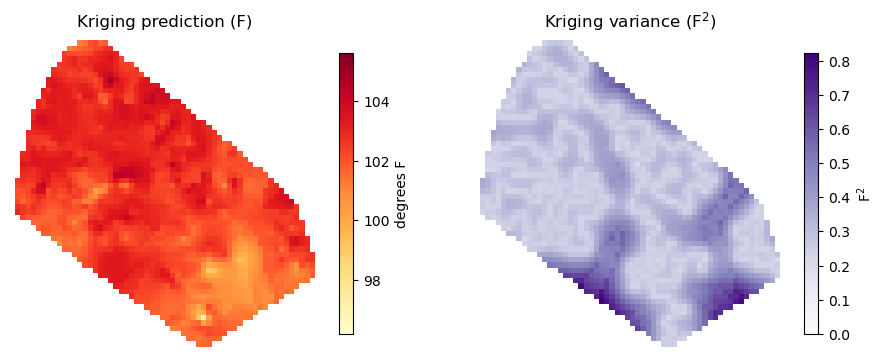

prediction range 97.2 to 105.0 F
variance range 0.21 to 0.82 F^2


In [12]:
model = models["exponential"]
pred, var = predict_krige(xy, t, U, fitted=model)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
im1 = show_surface(axes[0], gx, gy, pred, inside, vmin, vmax, "Kriging prediction (F)")
fig.colorbar(im1, ax=axes[0], shrink=0.7, label="degrees F")
im2 = show_surface(axes[1], gx, gy, var, inside, 0, np.nanmax(np.where(inside, var, np.nan)),
                   "Kriging variance (F$^2$)", cmap="Purples")
fig.colorbar(im2, ax=axes[1], shrink=0.7, label="F$^2$")
plt.show()
print(f"prediction range {pred[inside].min():.1f} to {pred[inside].max():.1f} F")
print(f"variance range {var[inside].min():.2f} to {var[inside].max():.2f} F^2")

The prediction map looks like the kNN maps. The variance map is what kNN cannot give you: it is lowest along the routes where sensors are dense and highest in gaps between routes and at the edge. Right next to a sensor the variance equals the nugget (0.21), because the only uncertainty left is the small-scale variation the model cannot resolve.

**Using the variance.** The difference between the highest and lowest variance cells is the case for putting the next sensor where variance is high.

In [13]:
def nearest_sensor(u):
    return np.sqrt(((xy - u) ** 2).sum(1)).min()

cells = np.where(inside)[0]
worst, best = cells[np.argmax(var[cells])], cells[np.argmin(var[cells])]
print(f"highest variance {var[worst]:.2f} F^2, nearest sensor {nearest_sensor(U[worst]):,.0f} m away")
print(f"lowest variance  {var[best]:.2f} F^2, nearest sensor {nearest_sensor(U[best]):,.0f} m away")

highest variance 0.82 F^2, nearest sensor 2,499 m away
lowest variance  0.21 F^2, nearest sensor 8 m away


**🔎 Try it yourself.** Predict with `no_neighbors=4` and `no_neighbors=40` (the `k` argument of `predict_krige`). How does the prediction range change, and how long does it take?

## Part 5. How good are these predictions?

**Cross-validation** hides some sensors, predicts them from the rest, and measures the error. Two numbers summarize the errors, in degrees F:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat z_i - z_i)^2}, \qquad \text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|\hat z_i - z_i|$$

- $z_i$ is the measured value at hidden point $i$ and $\hat z_i$ is the prediction made without it.
- $n$ is the number of hidden points.
- RMSE penalizes large errors more than MAE.

There are two ways to choose the hidden points:

- **Random 10-fold**: hide a random tenth of the points, predict them, repeat ten times.
- **Spatially blocked**: divide the study area into 5 km squares and hide one whole square at a time. This asks the question a map user asks: how good is the surface in a place where we have **no** nearby data?

Random folds leave neighbors of every hidden point in the training set, which makes prediction easy. A **baseline** of predicting the training mean shows how much any method adds.

In [14]:
from sklearn.model_selection import KFold, LeaveOneGroupOut


def cv_scores(xy, t, method, groups=None, seed=0, **kw):
    """Cross-validated RMSE and MAE. groups=None: random 10-fold. Otherwise: leave one group (block) out."""
    if groups is None:
        splits = list(KFold(10, shuffle=True, random_state=seed).split(xy))
    else:
        splits = list(LeaveOneGroupOut().split(xy, t, groups))
    pred = np.zeros(len(t))
    for train, test in splits:
        if method == "mean":
            pred[test] = t[train].mean()
        elif method == "knn":
            pred[test] = predict_knn(xy[train], t[train], xy[test], kw.get("k", 15))
        elif method == "krige":
            pred[test] = predict_krige(xy[train], t[train], xy[test])[0]
    err = pred - t
    return float(np.sqrt(np.mean(err ** 2))), float(np.mean(np.abs(err)))

In [15]:
blocks = block_ids(xy)
print(len(np.unique(blocks)), "blocks of 5 km")
rows = []
for label, method, kw in [("training mean", "mean", {}), ("nearest neighbor", "knn", {"k": 1}),
                          ("kNN distance, k = 15", "knn", {"k": 15}), ("ordinary kriging", "krige", {})]:
    r_rmse, r_mae = cv_scores(xy, t, method, None, **kw)
    b_rmse, b_mae = cv_scores(xy, t, method, blocks, **kw)
    rows.append([label, r_rmse, r_mae, b_rmse, b_mae])
table = pd.DataFrame(rows, columns=["method", "random RMSE", "random MAE", "blocked RMSE", "blocked MAE"]).set_index("method")
print(table.round(2))

18 blocks of 5 km
                      random RMSE  random MAE  blocked RMSE  blocked MAE
method                                                                  
training mean                0.92        0.70          0.94         0.72
nearest neighbor             0.51        0.36          0.86         0.63
kNN distance, k = 15         0.51        0.37          0.78         0.58
ordinary kriging             0.40        0.29          0.77         0.55


Random cross-validation makes every method look better than it is for a place with no nearby sensors. The blocked scores are what you should quote for a surface you will use to map places far from a sensor. They are also much closer to the training mean baseline: beyond the first few km, interpolation has little left to offer.

**🔎 Try it yourself.** Change the block size in `block_ids` to 2000 and to 10000. What happens to the blocked RMSE? (Hint: the 10 km blocks leave very large holes.)

## Part 6. Polygons to polygons: area weighting

Now the values live on polygons instead of points. The 2020 census counted people in **tracts**, and we want counts in **block groups** (smaller units, drawn differently). Moving values between two sets of boundaries that do not line up is also called interpolation.

**The data.** `dallas_tract_2020.gpkg` has 645 tracts for Dallas County with `pop` (people counted in the 2020 census, from the PL 94-171 redistricting file), `pct_rented` (percent of households that rent) and `median_age` (both from the 2024 American Community Survey, available for 588 tracts). `dallas_bg_2020.gpkg` has 1,570 block groups with their own 2020 counts, `pop`. Both are in EPSG:32614.

**Area weighting** has three steps:

1. **Overlay** the two layers. Each piece is one tract inside one block group.
2. **Share**: each piece's share of its tract is its area divided by the tract's area.
3. **Add up** the pieces in each block group.

How to add up depends on the kind of variable:

- An **extensive** variable (a count: people, households) is **split** by area share and **summed**. $\hat y_B = \sum_{T} y_T \cdot \dfrac{A_{T\cap B}}{A_T}$.
- An **intensive** variable (a rate, share or median) is **averaged**, weighted by area. $\hat y_B = \dfrac{\sum_{T} y_T \, A_{T\cap B}}{\sum_{T} A_{T\cap B}}$.

Here $y_T$ is the value in tract $T$, $B$ is a block group, $A_T$ is the area of the tract, and $A_{T\cap B}$ is the area of the part of the tract inside block group $B$. A count that is split keeps its total; a rate that is split would be nonsense, because half of a 40 percent rented rate is not a 20 percent rate.

In [16]:
tr = gpd.read_file("data/dallas_tract_2020.gpkg")
bg = gpd.read_file("data/dallas_bg_2020.gpkg")
print(len(tr), "tracts,", len(bg), "block groups; people:", f"{tr['pop'].sum():,}", "in tracts,", f"{bg['pop'].sum():,}", "in block groups")

645 tracts, 1570 block groups; people: 2,613,539 in tracts, 2,613,539 in block groups


In [17]:
def area_weight(source, target, extensive=(), intensive=()):
    """Move values from source polygons to target polygons by the share of area.
    extensive: counts (each source value is split by area share, so totals are kept).
    intensive: rates and medians (area-weighted average of the pieces that fall in each target)."""
    src = source.reset_index(drop=True).copy()
    src["src_id"], src["src_area"] = src.index, src.area
    tgt = target.reset_index(drop=True)[["geometry"]].copy()
    tgt["tgt_id"] = tgt.index
    cols = list(extensive) + list(intensive)
    pieces = gpd.overlay(src[["src_id", "src_area", *cols, "geometry"]], tgt, how="intersection")
    pieces["piece_area"] = pieces.area
    pieces["share"] = pieces["piece_area"] / pieces["src_area"]      # share of the source polygon in this piece
    out = pd.DataFrame(index=tgt.index)
    for c in extensive:
        out[c] = (pieces[c] * pieces["share"]).groupby(pieces["tgt_id"]).sum()
    for c in intensive:
        p = pieces.dropna(subset=[c])
        out[c] = (p[c] * p["piece_area"]).groupby(p["tgt_id"]).sum() / p.groupby("tgt_id")["piece_area"].sum()
    return out.reindex(tgt.index)

First, steps 1 and 2 for one tract, so you can see the pieces.

In [18]:
one = tr.iloc[[10]].reset_index(drop=True)
one["src_area"] = one.area
pieces = gpd.overlay(one[["GEOID", "pop", "src_area", "geometry"]], bg[["GEOID", "geometry"]].rename(columns={"GEOID": "bg"}),
                     how="intersection")
pieces["share"] = pieces.area / pieces["src_area"]
pieces["people"] = pieces["pop"] * pieces["share"]
print(f"tract {one.GEOID[0]}, {one['pop'][0]} people, area {one.src_area[0] / 1e6:.2f} km2")
print(pieces[["bg", "share", "people"]].round(3).to_string(index=False))
print("shares add to", pieces["share"].sum().round(3))

tract 48113018142, 3916 people, area 9.03 km2
          bg  share   people
481130181421  0.894 3499.268
481130181422  0.106  416.732
shares add to 1.0


In [19]:
est = area_weight(tr, bg, extensive=["pop"], intensive=["pct_rented", "median_age"])
print(f"people  tracts {tr['pop'].sum():,.0f}   block groups {est['pop'].sum():,.0f}")
print(f"pct renting  tracts {tr.pct_rented.min():.0f} to {tr.pct_rented.max():.0f}   block groups {est.pct_rented.min():.1f} to {est.pct_rented.max():.1f}")
print(f"median age   tracts {tr.median_age.min():.1f} to {tr.median_age.max():.1f}   block groups {est.median_age.min():.1f} to {est.median_age.max():.1f}")

people  tracts 2,613,539   block groups 2,613,539
pct renting  tracts 0 to 98   block groups 0.0 to 98.0
median age   tracts 19.0 to 61.6   block groups 19.0 to 61.6


The count keeps its total exactly: the shares of each tract add to 1, so every person lands in some block group. The rate and the median are averages of tract values, so no block group can be higher than the highest tract or lower than the lowest one. Here the extremes survive because a block group that lies entirely inside the highest (or lowest) tract keeps that tract's value. Away from the extremes, block groups take values between those of the tracts they overlap.

**🔎 Try it yourself.** Run `area_weight` with `pct_rented` listed under `extensive` instead of `intensive`. What total do you get, and does it mean anything?

## Part 7. Check against the truth

The census also published 2020 counts for block groups, so we can test the tract-to-block-group estimate against the real counts. That is rare: most of the time there is no truth to check against, which is why a method's behavior has to be understood.

Two summaries compare estimate $\hat y_B$ with the count $y_B$ over the $m$ block groups:

$$\text{MAE} = \frac{1}{m}\sum_{B}|\hat y_B - y_B|, \qquad r = \text{correlation of } \hat y_B \text{ with } y_B$$

MAE 529 people per block group (mean count 1665), r = 0.58


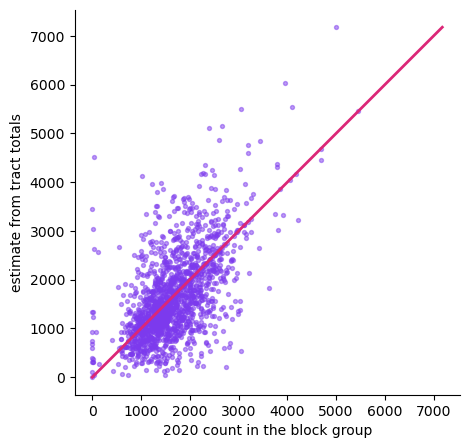

In [20]:
truth = bg["pop"].to_numpy()
guess = est["pop"].to_numpy()
err = guess - truth
print(f"MAE {np.abs(err).mean():.0f} people per block group (mean count {truth.mean():.0f}), r = {np.corrcoef(truth, guess)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(truth, guess, s=8, color=PURPLE, alpha=0.5)
mx = max(truth.max(), guess.max())
ax.plot([0, mx], [0, mx], color=MAGENTA, lw=2)
ax.set_xlabel("2020 count in the block group")
ax.set_ylabel("estimate from tract totals")
ax.set_aspect("equal")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Points on the magenta line are exact. Area weighting assumes people are spread evenly over each tract. Where a tract has a park, a lake or an industrial area in one part and homes in another, a block group that holds the homes has more people than its area share says, and one that holds the park has fewer.

**Do the errors cluster?** If errors in neighboring block groups have the same sign, the estimate is wrong in a region, not in scattered places. Moran's I (used on the temperatures in Part 1) answers this for the errors, with queen contiguity weights (polygons that touch):

In [21]:
from libpysal.weights import Queen
from esda.moran import Moran

w = Queen.from_dataframe(bg, silence_warnings=True)
w.transform = "r"
np.random.seed(0)
mi = Moran(err, w, permutations=999)
print(f"Moran's I of the errors = {mi.I:.2f} (p = {mi.p_sim:.3f})")

worst = bg.assign(err=err).reindex(np.abs(err).argsort()[::-1][:3])
print(worst[["GEOID", "pop", "err"]].round(0).to_string(index=False))

Moran's I of the errors = -0.08 (p = 0.001)
       GEOID  pop    err
481130141263   29 4481.0
481130190405    0 3442.0
481130080004 1012 3113.0


Moran's I of the errors is slightly **negative**, so the errors do not cluster by sign. That fits how area weighting works: a tract is cut between two block groups, and when one gets too many people the other gets too few. The three largest errors, all over-estimates of thousands of people in block groups whose true counts are 0 to about 1,000, name the places to look at first: where "evenly spread" is least true.

**What would improve it.** Replace "area" with a better guess of where people live, such as built-up area (dasymetric mapping) or a smoothness constraint (pycnophylactic interpolation). Both are in Going Further.

## Learn More / Going Further

**1. Ozone monitors: when interpolation barely helps.** `data/dfw_ozone_2024.csv` holds the 2024 EPA annual summary for the Dallas-Fort Worth area. There are only 18 ozone sites. Leave one out, predict it from the other 17, and compare with predicting the mean of the other 17.

In [22]:
o = pd.read_csv("data/dfw_ozone_2024.csv", low_memory=False)
o = o[(o["Pollutant Standard"] == "Ozone 8-hour 2015") & (o["Metric Used"].str.contains("8-hour|8 hour"))]
s = o.groupby(["Latitude", "Longitude"], as_index=False).agg(ppb=("Arithmetic Mean", "mean"))
s["ppb"] *= 1000
sites = gpd.GeoDataFrame(s, geometry=gpd.points_from_xy(s.Longitude, s.Latitude), crs=4326).to_crs(32614)
sxy = np.column_stack([sites.geometry.x, sites.geometry.y])
sz = sites["ppb"].to_numpy()

loo = {"mean": [], "kNN k = 5": []}
for i in range(len(sz)):
    rest = np.delete(np.arange(len(sz)), i)
    loo["mean"].append(sz[rest].mean())
    loo["kNN k = 5"].append(predict_knn(sxy[rest], sz[rest], sxy[[i]], k=5)[0])
print(len(sz), "sites; SD of the site values", sz.std().round(2), "ppb")
for name, p in loo.items():
    print(f"{name:10s} leave-one-out RMSE {np.sqrt(np.mean((np.array(p) - sz) ** 2)):.2f} ppb")

18 sites; SD of the site values 2.62 ppb
mean       leave-one-out RMSE 2.78 ppb
kNN k = 5  leave-one-out RMSE 2.71 ppb


The two are nearly the same: with 18 sites and values that barely vary, the spatial structure is too weak to beat the mean. A smooth map from such a network looks authoritative and says little.

**2. Dasymetric and pycnophylactic interpolation (not run in this environment).** The `tobler` package needs Python 3.12 and is not installed here. With it, the tract-to-block-group estimate in Part 7 uses a built-up-area mask or a smoothness constraint:

```python
from tobler.area_weighted import area_interpolate
from tobler.dasymetric import masked_area_interpolate
from tobler.pycno import pycno_interpolate
by_area = area_interpolate(tr, bg, extensive_variables=["pop"])
by_built = masked_area_interpolate(tr, bg, raster="dallas_builtup_30m.tif", pixel_values=[1], extensive_variables=["pop"])
by_smooth = pycno_interpolate(tr, bg, variables=["pop"], cellsize=250)
```

In the lecture's run, mean absolute error was 421 people per block group with the built-up mask, 529 with plain area and 536 with pycnophylactic interpolation. (`masked_area_interpolate` is much slower than the others at fine raster cell sizes.)

**3. Stretch: how many people live within half a mile of a rail station?** `data/dart_rail_stops.csv` has DART rail stops (`stop_lat`, `stop_lon`). Buffer each stop by 804.67 m, project to EPSG:32614, and use `area_weight(tr, circles, extensive=["pop"])` to estimate the people inside each circle. Which stops have the largest catchments? Which circles overlap so that people are counted twice?

**4. Stretch: precincts to congressional districts.** Voting precincts (the Voting and Election Science Team's 2020 file) do not nest in congressional districts that were redrawn in 2023. The same `area_weight` function moves precinct vote counts (extensive) to district lines. Compute a district's share of votes for one candidate from the moved counts, not from the moved shares.

**5. Stretch: different years, different tracts.** `data/dallas_tract_2010.gpkg` has 529 tracts with `pop10`. Move the 2010 counts onto the 2020 tracts with `area_weight` and compare totals. Which 2020 tracts changed most, and are they where tracts were split or where people moved?

**6. Optional task: write ordinary kriging yourself.** See the last task in `lab10-tasks-solutions.ipynb`.

**7. Read further.** Roberts et al. (2017), *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*, Ecography 40(8), 913-929, is the standard reference for blocked cross-validation. The `pyinterpolate` documentation (https://pyinterpolate.readthedocs.io) covers other variogram models and kriging variants.